Agora vamos criar gráficos de Candlestick com Matplotlib (uma biblioteca para criar gráficos e visualizações de dados).

Vamos começar importando as bibliotecas que vamos utilizar

In [1]:
# Se necessário, instale as dependências listadas no requirements.txt

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import mplfinance as mpf
import yfinance as yf
import plotly.graph_objects as go
from plotly.subplots import make_subplots

Agora vamos importar os nossos dados, só que não do Excel nem de outro lugar: vamos usar o yfinance (yf).

O yfinance é uma biblioteca Python que busca dados financeiros do Yahoo Finance. Não é uma API oficial da bolsa.

Para baixar os dados temos que ter o código da ação. Vamos chamar a Petrobras (PETR4.SA). E tem que colocar também o período que queremos analisar.

As datas ficam no formato ano-mês-dia (AAAA-MM-DD).

In [3]:
dados = yf.download('PETR4.SA', start='2023-01-01', end='2023-12-31', auto_adjust=False, progress=False)
# O yfinance pode devolver colunas em MultiIndex; aqui deixamos apenas o nível com os preços.
if isinstance(dados.columns, pd.MultiIndex):
    dados.columns = dados.columns.get_level_values(0)
dados

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2023-01-02,12.196249,22.920000,23.809999,22.799999,23.540001,78424700
2023-01-03,11.887620,22.340000,23.100000,22.129999,22.940001,96750300
2023-01-04,12.265426,23.049999,23.590000,21.830000,21.959999,129504000
2023-01-05,12.707085,23.879999,24.040001,23.150000,23.340000,73886000
2023-01-06,12.632591,23.740000,24.320000,23.549999,23.940001,51851500
...,...,...,...,...,...,...
2023-12-21,25.072678,36.389999,36.680000,36.070000,36.669998,30511900
2023-12-22,25.313835,36.740002,36.799999,36.369999,36.500000,31234700
2023-12-26,25.720339,37.330002,37.369999,36.830002,36.860001,23466800


Vamos conferir as colunas e depois renomear para português. Dependendo da versão do yfinance, elas podem vir com nomes ou níveis diferentes.

In [4]:
dados.columns

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='str',
      name='Price')

Agora que a gente tem os nomes, vamos escolher os nomes em português correspondentes, sem trocar a ordem dos dados.

In [5]:
# Renomear pelo nome original, sem depender da ordem das colunas
dados = dados.rename(columns={
    'Open': 'Abertura', 'High': 'Maximo', 'Low': 'Minimo',
    'Close': 'Fechamento', 'Adj Close': 'Fech_Ajust', 'Volume': 'Volume'
})


In [6]:
dados

Price,Fech_Ajust,Fechamento,Maximo,Minimo,Abertura,Volume
Date,,,,,,
2023-01-02,12.196249,22.920000,23.809999,22.799999,23.540001,78424700
2023-01-03,11.887620,22.340000,23.100000,22.129999,22.940001,96750300
2023-01-04,12.265426,23.049999,23.590000,21.830000,21.959999,129504000
2023-01-05,12.707085,23.879999,24.040001,23.150000,23.340000,73886000
2023-01-06,12.632591,23.740000,24.320000,23.549999,23.940001,51851500
...,...,...,...,...,...,...
2023-12-21,25.072678,36.389999,36.680000,36.070000,36.669998,30511900
2023-12-22,25.313835,36.740002,36.799999,36.369999,36.500000,31234700
2023-12-26,25.720339,37.330002,37.369999,36.830002,36.860001,23466800


A data está no índice da tabela (aparece como Date), e não como uma coluna comum. Agora vamos mudar o nome desse eixo do índice para Data.

.rename_axis renomeia o eixo do índice, não uma coluna.

In [7]:
dados = dados.rename_axis('Data')
dados

Price,Fech_Ajust,Fechamento,Maximo,Minimo,Abertura,Volume
Data,,,,,,
2023-01-02,12.196249,22.920000,23.809999,22.799999,23.540001,78424700
2023-01-03,11.887620,22.340000,23.100000,22.129999,22.940001,96750300
2023-01-04,12.265426,23.049999,23.590000,21.830000,21.959999,129504000
2023-01-05,12.707085,23.879999,24.040001,23.150000,23.340000,73886000
2023-01-06,12.632591,23.740000,24.320000,23.549999,23.940001,51851500
...,...,...,...,...,...,...
2023-12-21,25.072678,36.389999,36.680000,36.070000,36.669998,30511900
2023-12-22,25.313835,36.740002,36.799999,36.369999,36.500000,31234700
2023-12-26,25.720339,37.330002,37.369999,36.830002,36.860001,23466800


Criando o primeiro gráfico (na primeira linha)

Adicionamos o título desse gráfico (segunda linha)
E colocamos a legenda (terceira linha)

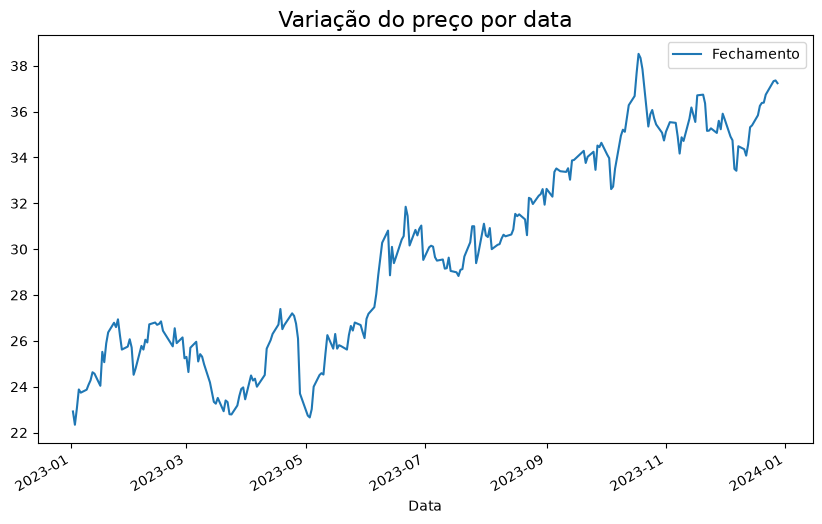

In [8]:
dados['Fechamento'].plot(figsize=(10,6))
plt.title('Variação do preço por data', fontsize=16)
plt.legend(['Fechamento'])

Começando aqui a base para criar o gráfico de Candlestick

In [9]:
df = dados.head(60).copy()

# Convertendo o índice em uma coluna de data
df['Data'] = df.index

# Convertendo as datas para o formato numérico de matplotlib
# Isso é necessário para que o Matplotlib possa plotar as datas corretamente no gráfico
df['Data'] = df['Data'].apply(mdates.date2num)

df

Price,Fech_Ajust,Fechamento,Maximo,Minimo,Abertura,Volume,Data
Data,,,,,,,
2023-01-02,12.196249,22.920000,23.809999,22.799999,23.540001,78424700,19359.0
2023-01-03,11.887620,22.340000,23.100000,22.129999,22.940001,96750300,19360.0
2023-01-04,12.265426,23.049999,23.590000,21.830000,21.959999,129504000,19361.0
2023-01-05,12.707085,23.879999,24.040001,23.150000,23.340000,73886000,19362.0
2023-01-06,12.632591,23.740000,24.320000,23.549999,23.940001,51851500,19363.0
2023-01-09,12.701767,23.870001,24.000000,23.250000,23.500000,46385200,19366.0
2023-01-10,12.818832,24.090000,24.110001,23.370001,23.950001,52741100,19367.0
2023-01-11,12.919934,24.280001,24.620001,24.049999,24.150000,53536500,19368.0
2023-01-12,13.106178,24.629999,24.650000,24.110001,24.290001,58130000,19369.0


Com a base pronta, temos que criar de fato o nosso gráfico

Estamos criando nossa tela inicial aqui

(For é o comando de repetição)

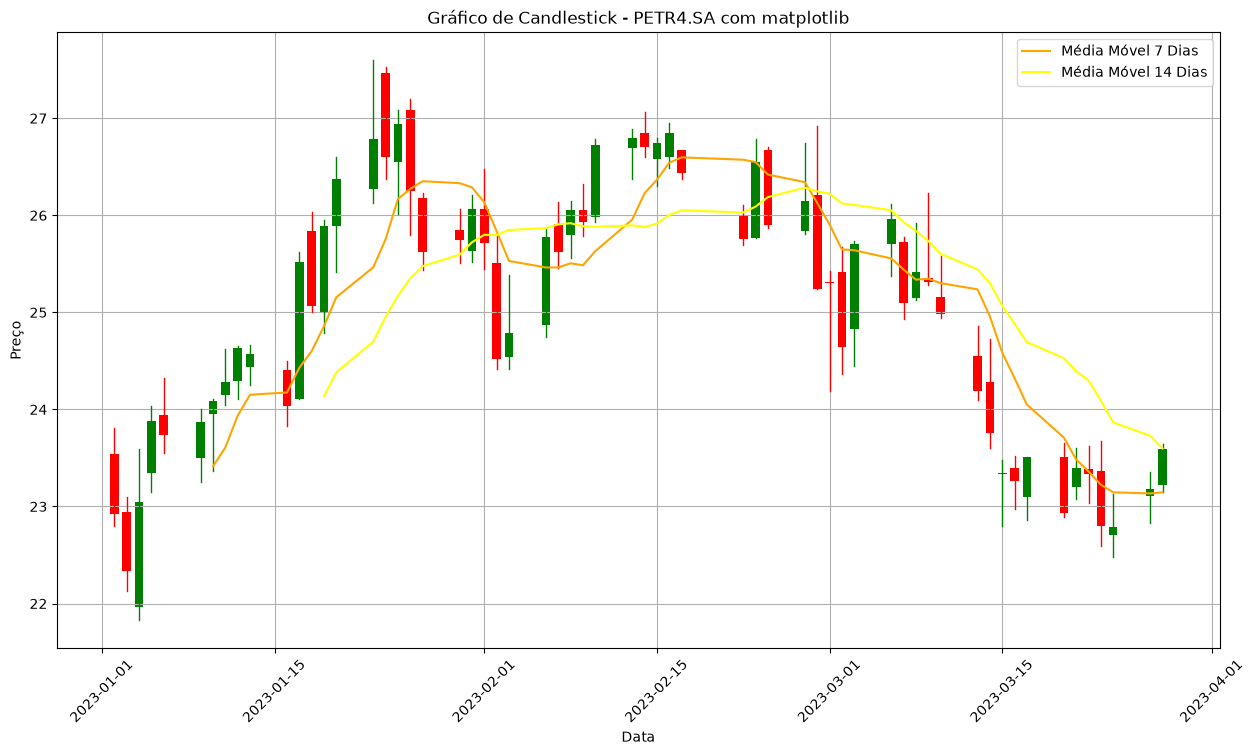

In [10]:
fig, ax = plt.subplots(figsize=(15, 8))

# Vamos definir a largura dos candles no gráfico
width = 0.7

for i in range(len(df)):
    # Determinando a cor do candle
    # Se o preço de fechamento for maior que o de abertura, o candle é verde (a ação valorizou nesse dia).
    # Se for menor, o candle é vermelho (a ação desvalorizou).
    if df['Fechamento'].iloc[i] > df['Abertura'].iloc[i]:
        color = 'green'
    else:
        color = 'red'

    # Desenhando a linha vertical do candle (mecha)
    # Essa linha mostra os preços máximo (topo da linha) e mínimo (base da linha) do dia.
    # Usamos `ax.plot` para desenhar uma linha vertical.
    # [df['Data'].iloc[i], df['Data'].iloc[i]] define o ponto x da linha (a data), e [df['Mínimo'].iloc[i], df['Máximo'].iloc[i]] define a altura da linha.
    ax.plot([df['Data'].iloc[i], df['Data'].iloc[i]],
            [df['Minimo'].iloc[i], df['Maximo'].iloc[i]],
            color=color,
            linewidth=1)

    ax.add_patch(plt.Rectangle((df['Data'].iloc[i] - width/2, min(df['Abertura'].iloc[i], df['Fechamento'].iloc[i])),
                               width,
                               abs(df['Fechamento'].iloc[i] - df['Abertura'].iloc[i]),
                               facecolor=color))

df['MA7'] = df['Fechamento'].rolling(window=7).mean()
df['MA14'] = df['Fechamento'].rolling(window=14).mean()

# Plotando as médias móveis
ax.plot(df['Data'], df['MA7'], color='orange', label='Média Móvel 7 Dias')  # Média de 7 dias
ax.plot(df['Data'], df['MA14'], color='yellow', label='Média Móvel 14 Dias')  # Média de 14 dias
# Adicionando legendas para as médias móveis
ax.legend()

# Formatando o eixo x para mostrar as datas
# Configuramos o formato da data e a rotação para melhor legibilidade
ax.xaxis_date() #O método xaxis_date() é usado para dizer ao Matplotlib que as datas estão sendo usadas no eixo x
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.xticks(rotation=45)

# Adicionando título e rótulos para os eixos x e y
plt.title("Gráfico de Candlestick - PETR4.SA com matplotlib")
plt.xlabel("Data")
plt.ylabel("Preço")

# Adicionando uma grade para facilitar a visualização dos valores
plt.grid(True)

# Exibindo o gráfico
plt.show()

O que a gente fez tá estático, oq vamos fazer é tornar interativo

In [11]:
# Criando subplots
'''
"Primeiro, criamos uma figura que conterá nossos gráficos usando make_subplots.
Isso nos permite ter múltiplos gráficos em uma única visualização.
Aqui, teremos dois subplots: um para o gráfico de candlestick e outro para o volume de transações."

'''
fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                    vertical_spacing=0.1,
                    subplot_titles=('Candlesticks', 'Volume Transacionado'),
                    row_width=[0.2, 0.7])

'''
"No gráfico de candlestick, cada candle representa um dia de negociação,
mostrando o preço de abertura, fechamento, máximo e mínimo. Vamos adicionar este gráfico à nossa figura."
'''
# Adicionando o gráfico de candlestick
fig.add_trace(go.Candlestick(x=df.index,
                             open=df['Abertura'],
                             high=df['Maximo'],
                             low=df['Minimo'],
                             close=df['Fechamento'],
                             name='Candlestick'),
                             row=1, col=1)

# Adicionando as médias móveis
# Adicionamos também médias móveis ao mesmo subplot para análise de tendências
fig.add_trace(go.Scatter(x=df.index,
                         y=df['MA7'],
                         mode='lines',
                         name='MA7 - Média Móvel 7 Dias'),
                         row=1, col=1)

fig.add_trace(go.Scatter(x=df.index,
                         y=df['MA14'],
                         mode='lines',
                         name='MA14 - Média Móvel 14 Dias'),
                         row=1, col=1)

# Adicionando o gráfico de barras para o volume
# Em seguida, criamos um gráfico de barras para o volume de transações, que nos dá uma ideia da atividade de negociação naquele dia
fig.add_trace(go.Bar(x=df.index,
                     y=df['Volume'],
                     name='Volume'),
                     row=2, col=1)

# Atualizando layout
#Finalmente, configuramos o layout da figura, ajustando títulos, formatos de eixo e outras configurações para tornar o gráfico claro e legível.
fig.update_layout(yaxis_title='Preço',
                  xaxis_rangeslider_visible=False,  # Desativa o range slider
                  width=1100, height=600)

# Mostrando o gráfico
fig.show()


Agora vamos usar o mplfinance para fazer um gráfico de candlestick com menos código!

Os dois comandos abaixo baixam dados de outra ação (Apple) e montam o gráfico, mas não reproduzem todas as personalizações que fizemos acima.

In [12]:
dados = yf.download('AAPL', start='2023-01-01', end='2023-12-31', auto_adjust=False, progress=False)
if isinstance(dados.columns, pd.MultiIndex):
    dados.columns = dados.columns.get_level_values(0)
dados = dados[['Open', 'High', 'Low', 'Close', 'Volume']].copy()

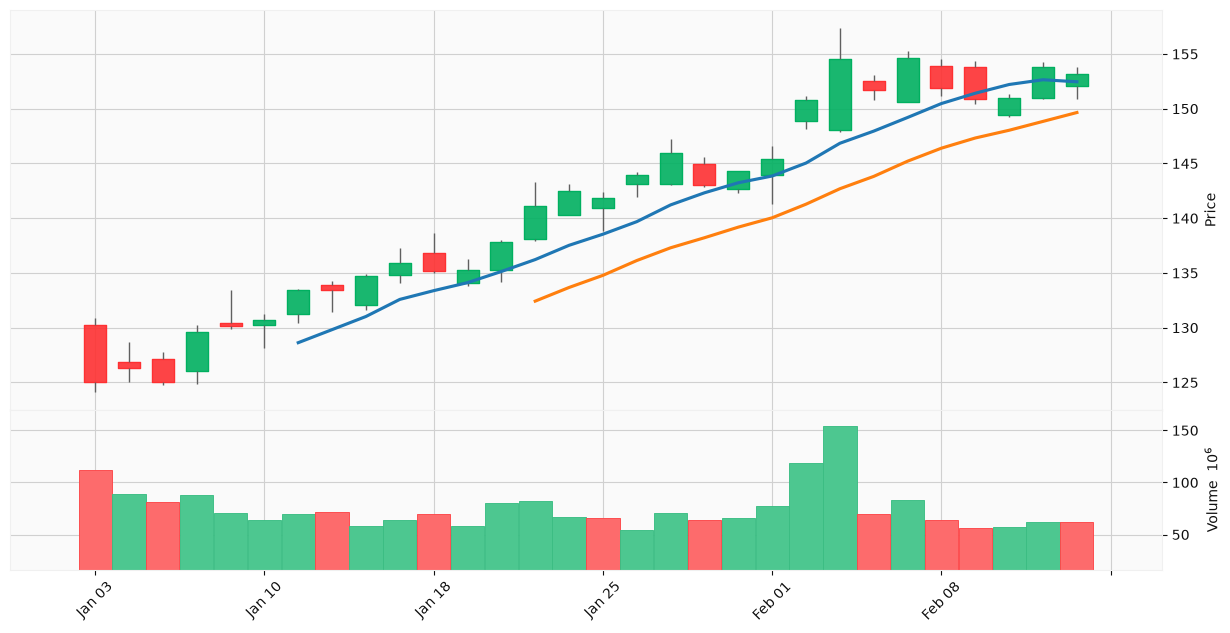

In [13]:
mpf.plot(dados.head(30), type='candle', figsize = (16,8), volume=True, mav=(7,14), style='yahoo')